# Predictive Maintenance: Machine Learning

## Objective
Develop a machine-learning model to identify potential equipment failures using industrial sensor measurements.

## Modelling Approach
1. Load and prepare the dataset.
2. Select relevant features and the target variable.
3. Split the data into training and testing sets.
4. Establish a baseline model.
5. Train a classification model.
6. Evaluate performance using precision, recall, F1-score and a confusion matrix.

## Important Consideration
Equipment failures are relatively rare in this dataset. Therefore, accuracy alone is not sufficient to evaluate model performance.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

cwd = Path.cwd()

if (cwd / "data" / "raw" / "ai4i2020.csv").exists():
    PROJECT_ROOT = cwd
else:
    PROJECT_ROOT = cwd.parent

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "ai4i2020.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [2]:
df["Machine failure"].value_counts()

Machine failure
0    9661
1     339
Name: count, dtype: int64

In [3]:
df["Machine failure"].value_counts(normalize=True).mul(100).round(2)

Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64

In [4]:
features = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

X = df[features]
y = df["Machine failure"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (10000, 6)
Target shape: (10000,)


In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nFailures in training data:", y_train.sum())
print("Failures in testing data:", y_test.sum())

Training features: (8000, 6)
Testing features: (2000, 6)

Failures in training data: 271
Failures in testing data: 68


In [6]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [7]:
baseline_model = DummyClassifier(strategy="most_frequent")

baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)

print("Baseline model trained successfully!")

Baseline model trained successfully!


In [8]:
baseline_accuracy = accuracy_score(
    y_test,
    baseline_predictions
)

print(f"Baseline Accuracy: {baseline_accuracy * 100:.2f}%")

Baseline Accuracy: 96.60%


In [9]:
print(classification_report(
    y_test,
    baseline_predictions,
    zero_division=0
))

              precision    recall  f1-score   support

           0       0.97      1.00      0.98      1932
           1       0.00      0.00      0.00        68

    accuracy                           0.97      2000
   macro avg       0.48      0.50      0.49      2000
weighted avg       0.93      0.97      0.95      2000



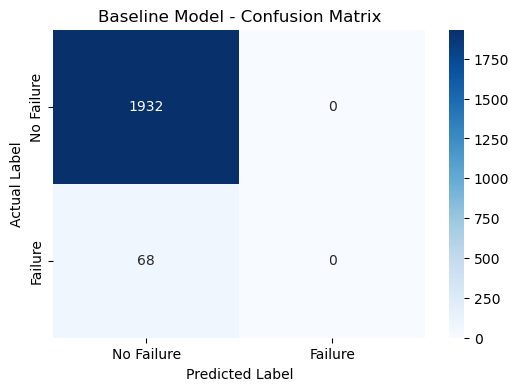

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

baseline_cm = confusion_matrix(
    y_test,
    baseline_predictions
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    baseline_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Failure", "Failure"],
    yticklabels=["No Failure", "Failure"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Baseline Model - Confusion Matrix")
plt.show()

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Identify numerical and categorical features
categorical_features = ["Type"]

numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

# Prepare the features
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("numerical", StandardScaler(), numerical_features)
    ]
)

# Create the complete machine-learning pipeline
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=42
        ))
    ]
)

print("Model pipeline created successfully!")

Model pipeline created successfully!


In [12]:
model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [13]:
y_pred = model.predict(X_test)

print("Predictions generated successfully!")
print("First 20 predictions:", y_pred[:20])

Predictions generated successfully!
First 20 predictions: [1 1 1 0 1 1 1 0 0 1 0 0 0 0 0 1 0 1 0 0]


In [14]:
from sklearn.metrics import accuracy_score, classification_report

model_accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {model_accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Failure", "Failure"],
    zero_division=0
))

Model Accuracy: 82.45%

Classification Report:
              precision    recall  f1-score   support

  No Failure       0.99      0.82      0.90      1932
     Failure       0.14      0.82      0.24        68

    accuracy                           0.82      2000
   macro avg       0.57      0.82      0.57      2000
weighted avg       0.96      0.82      0.88      2000



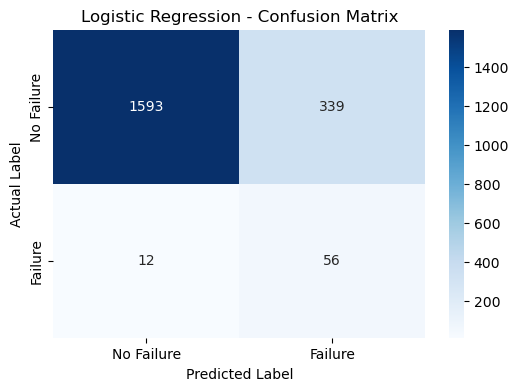

In [15]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Failure", "Failure"],
    yticklabels=["No Failure", "Failure"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Logistic Regression - Confusion Matrix")

plt.show()

In [16]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline(
    steps=[
        ("preprocessor", ColumnTransformer(
            transformers=[
                ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
                ("numerical", "passthrough", numerical_features)
            ]
        )),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [17]:
rf_pred = rf_model.predict(X_test)

print("Random Forest Results")
print("-" * 30)

print(
    f"Accuracy: {accuracy_score(y_test, rf_pred) * 100:.2f}%"
)

print(
    classification_report(
        y_test,
        rf_pred,
        target_names=["No Failure", "Failure"],
        zero_division=0
    )
)

Random Forest Results
------------------------------
Accuracy: 98.00%
              precision    recall  f1-score   support

  No Failure       0.98      1.00      0.99      1932
     Failure       0.94      0.44      0.60        68

    accuracy                           0.98      2000
   macro avg       0.96      0.72      0.79      2000
weighted avg       0.98      0.98      0.98      2000



In [18]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = pd.DataFrame([
    {
        "Model": "Baseline",
        "Accuracy": accuracy_score(y_test, baseline_predictions),
        "Failure Precision": precision_score(
            y_test, baseline_predictions, zero_division=0
        ),
        "Failure Recall": recall_score(
            y_test, baseline_predictions, zero_division=0
        ),
        "Failure F1": f1_score(
            y_test, baseline_predictions, zero_division=0
        )
    },
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, y_pred),
        "Failure Precision": precision_score(y_test, y_pred, zero_division=0),
        "Failure Recall": recall_score(y_test, y_pred, zero_division=0),
        "Failure F1": f1_score(y_test, y_pred, zero_division=0)
    },
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, rf_pred),
        "Failure Precision": precision_score(y_test, rf_pred, zero_division=0),
        "Failure Recall": recall_score(y_test, rf_pred, zero_division=0),
        "Failure F1": f1_score(y_test, rf_pred, zero_division=0)
    }
])

results = results.round(3)

results

,Model,Accuracy,Failure Precision,Failure Recall,Failure F1
0,Baseline,0.966,0.000,0.000,0.000
1,Logistic Regression,0.824,0.142,0.824,0.242
2,Random Forest,0.980,0.938,0.441,0.600


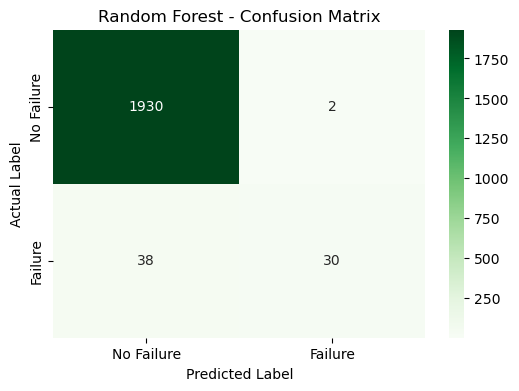

In [19]:
rf_cm = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["No Failure", "Failure"],
    yticklabels=["No Failure", "Failure"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Random Forest - Confusion Matrix")

plt.show()

In [21]:
# Probability that each test example belongs to the failure class
rf_probabilities = rf_model.predict_proba(X_test)[:, 1]

print("First 10 failure probabilities:")
print(rf_probabilities[:10])

First 10 failure probabilities:
[0.13  0.    0.035 0.01  0.085 0.    0.01  0.    0.    0.035]


In [22]:
from sklearn.metrics import precision_score, recall_score, f1_score

threshold_results = []

for threshold in [0.1, 0.2, 0.3, 0.4, 0.5]:
    predictions = (rf_probabilities >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0),
        "Predicted Failures": int(predictions.sum())
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df.round(3)

,Threshold,Precision,Recall,F1 Score,Predicted Failures
0,0.1,0.397,0.853,0.542,146
1,0.2,0.581,0.794,0.671,93
2,0.3,0.746,0.691,0.718,63
3,0.4,0.857,0.618,0.718,49
4,0.5,0.909,0.441,0.594,33


In [23]:
# Extract the trained Random Forest classifier
rf_classifier = rf_model.named_steps["classifier"]

# Get feature importance scores
importance_values = rf_classifier.feature_importances_

# Get the feature names after preprocessing
feature_names = rf_model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Create a feature importance table
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

importance_df.round(4)

,Feature,Importance
5,numerical__Rotational speed [rpm],0.3105
6,numerical__Torque [Nm],0.2879
7,numerical__Tool wear [min],0.2024
3,numerical__Air temperature [K],0.1054
4,numerical__Process temperature [K],0.0736
1,categorical__Type_L,0.0094
2,categorical__Type_M,0.0065
0,categorical__Type_H,0.0044


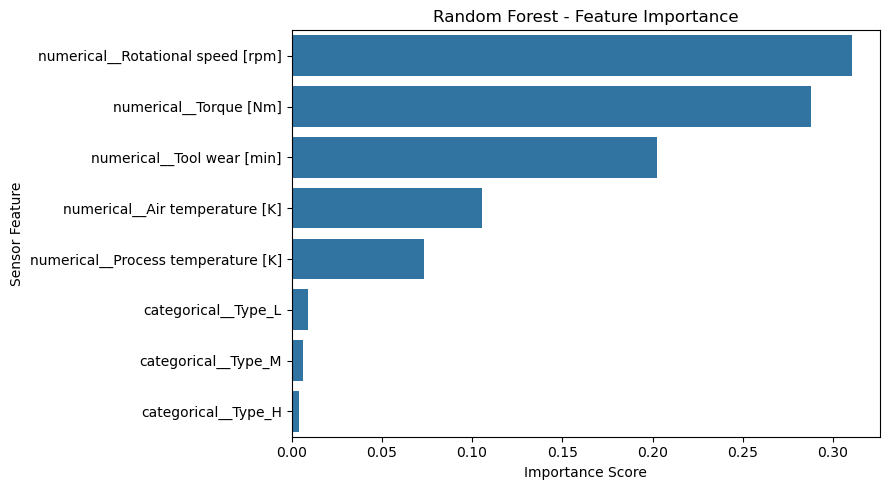

In [24]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest - Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Sensor Feature")
plt.tight_layout()
plt.show()

In [25]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import pandas as pd
import numpy as np

print("All imports successful!")

All imports successful!


In [26]:
X_train_inner, X_val, y_train_inner, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training rows:", len(X_train_inner))
print("Validation rows:", len(X_val))
print("Final test rows:", len(X_test))

print("\nFailure counts:")
print("Training:", y_train_inner.sum())
print("Validation:", y_val.sum())
print("Test:", y_test.sum())

Training rows: 6400
Validation rows: 1600
Final test rows: 2000

Failure counts:
Training: 217
Validation: 54
Test: 68


In [27]:
# Create a new Random Forest pipeline

rf_validation_model = Pipeline(
    steps=[
        (
            "preprocessor",
            ColumnTransformer(
                transformers=[
                    (
                        "categorical",
                        OneHotEncoder(handle_unknown="ignore"),
                        categorical_features
                    ),
                    (
                        "numerical",
                        "passthrough",
                        numerical_features
                    )
                ]
            )
        ),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

# Train using only the inner training set
rf_validation_model.fit(X_train_inner, y_train_inner)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [28]:
# Predict failure probabilities for the validation set
val_probabilities = rf_validation_model.predict_proba(X_val)[:, 1]

print("First 10 predicted failure probabilities:")
print(np.round(val_probabilities[:10], 3))

First 10 predicted failure probabilities:
[0.    0.03  0.    0.01  0.005 0.61  0.015 0.    0.    0.   ]


In [29]:
from sklearn.metrics import precision_score, recall_score, f1_score

threshold_results = []

for threshold in [0.1, 0.2, 0.3, 0.4, 0.5]:

    # Convert probabilities into predictions
    val_predictions = (
        val_probabilities >= threshold
    ).astype(int)

    # Calculate evaluation metrics
    precision = precision_score(
        y_val, val_predictions, zero_division=0
    )

    recall = recall_score(
        y_val, val_predictions, zero_division=0
    )

    f1 = f1_score(
        y_val, val_predictions, zero_division=0
    )

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "Predicted Failures": int(val_predictions.sum())
    })

# Display the results
threshold_df = pd.DataFrame(threshold_results)

threshold_df.round(3)

,Threshold,Precision,Recall,F1 Score,Predicted Failures
0,0.1,0.341,0.815,0.481,129
1,0.2,0.554,0.759,0.641,74
2,0.3,0.630,0.630,0.630,54
3,0.4,0.821,0.593,0.688,39
4,0.5,0.917,0.407,0.564,24


In [30]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Predict failure probabilities on the final test set
test_probabilities = rf_validation_model.predict_proba(X_test)[:, 1]

# Apply the threshold selected using validation data
chosen_threshold = 0.4

test_predictions = (
    test_probabilities >= chosen_threshold
).astype(int)

# Evaluate the final model
print("Chosen threshold:", chosen_threshold)
print("Test accuracy:", round(accuracy_score(y_test, test_predictions), 4))
print("Test precision:", round(precision_score(y_test, test_predictions, zero_division=0), 4))
print("Test recall:", round(recall_score(y_test, test_predictions, zero_division=0), 4))
print("Test F1 score:", round(f1_score(y_test, test_predictions, zero_division=0), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_predictions))

print("\nClassification Report:")
print(classification_report(y_test, test_predictions, zero_division=0))

Chosen threshold: 0.4
Test accuracy: 0.9805
Test precision: 0.8372
Test recall: 0.5294
Test F1 score: 0.6486

Confusion Matrix:
[[1925    7]
 [  32   36]]

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1932
           1       0.84      0.53      0.65        68

    accuracy                           0.98      2000
   macro avg       0.91      0.76      0.82      2000
weighted avg       0.98      0.98      0.98      2000



In [31]:
comparison_df = pd.DataFrame({
    "Model": [
        "Dummy Baseline",
        "Random Forest (Threshold 0.4)"
    ],
    "Accuracy": [
        accuracy_score(y_test, baseline_predictions),
        accuracy_score(y_test, test_predictions)
    ],
    "Precision": [
        precision_score(y_test, baseline_predictions, zero_division=0),
        precision_score(y_test, test_predictions, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, baseline_predictions, zero_division=0),
        recall_score(y_test, test_predictions, zero_division=0)
    ],
    "F1 Score": [
        f1_score(y_test, baseline_predictions, zero_division=0),
        f1_score(y_test, test_predictions, zero_division=0)
    ]
})

comparison_df.round(4)

,Model,Accuracy,Precision,Recall,F1 Score
0,Dummy Baseline,0.9660,0.0000,0.0000,0.0000
1,Random Forest (Threshold 0.4),0.9805,0.8372,0.5294,0.6486


In [32]:
from pathlib import Path
import joblib

# Create the models directory if it doesn't exist
models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

# Save the trained pipeline
model_path = models_dir / "random_forest_model.joblib"

joblib.dump(rf_validation_model, model_path)

print("Model saved successfully!")
print("Saved location:", model_path.resolve())

Model saved successfully!
Saved location: C:\Projects\Predictive Maintanence Project\models\random_forest_model.joblib


In [33]:
import joblib

loaded_model = joblib.load(model_path)

print("Model loaded successfully!")
print("Model type:", type(loaded_model).__name__)

Model loaded successfully!
Model type: Pipeline
